# EDA: Raw Data

**Goal:** understand the raw files well enough to write the first two functions in `combine.py`:
1. stack the 98 SA Water CSVs into one table → `data/interim/`
2. stack the 11 BoM `_Data1.csv` files into one table → `data/interim/`

This notebook only *looks* at the data. Anything decided here becomes code in `combine.py`.

In [2]:
import pandas as pd
from forecast import configure

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

SAWATER_DIR = configure.DATA_RAW_SAWATER
BOM_DIR = configure.DATA_RAW_BOM

## SA Water reservoir CSVs

### 1.1 Files
How many files and is the naming convention consistent?

In [3]:
sawater_files = sorted(SAWATER_DIR.glob("*.csv"))
print(len(sawater_files), "files")
print("first 5:", [f.name for f in sawater_files[:5]])
print("last 5: ", [f.name for f in sawater_files[-5:]])

98 files
first 5: ['reservoir-volumes-for-april-2024.csv', 'reservoir-volumes-for-april-2026.csv', 'reservoir-volumes-for-august-2024.csv', 'reservoir-volumes-for-august-2025.csv', 'reservoir-volumes-for-december-2025.csv']
last 5:  ['sawpfsc02homeve002087desktopopen-datareservoirvolumesforjune2018.csv', 'sawpfsc02homeve002087desktopreservoirvolumesforaugust2018.csv', 'sawpfsc02homeve002087desktopreservoirvolumesfordecember2018.csv', 'sawpfsc02homeve002087desktopreservoirvolumesforoctober2018.csv', 'sawpfsc02homeve002087desktopreservoirvolumesforseptember2018.csv']


#### Follow-Up: Sample a File

In [4]:
sample = pd.read_csv(sawater_files[-1], dtype=str)
print(sample.shape)
sample

(10, 8)


,Date,Reservoir Name,Capacity__ML_,Volume_today__ML_,Volume_this_Day_last_year__ML_,Average_Volume_this_Month,Latitude,Longitude
0,29-Sep-18,Mt Bold Reservoir,46545,26105.9,42590.57,25619.51,-35.12,138.71
1,29-Sep-18,Happy Valley Reservoir,12650,10221.53,11862.43,10401.15,-35.07,138.57
2,29-Sep-18,Millbrook Reservoir,15715,9124.95,14450.17,9310.33,-34.83,138.81
3,29-Sep-18,Kangaroo Creek Reservoir,18685,7814.71,11648.29,6994.19,-34.86,138.79
4,29-Sep-18,Hope Valley Reservoir,2935,1740.82,2750.8,2217.07,-34.85,138.69
5,29-Sep-18,Myponga Reservoir,27565,24113.34,26109.99,24141.14,-35.4,138.44
6,29-Sep-18,Warren Reservoir,4711,3704.6,4538.61,3855.84,-34.71,138.92
7,29-Sep-18,South Para Reservoir,44435,25566.48,43501.03,26139.19,-34.7,138.87
8,29-Sep-18,Barossa Reservoir,4375,4088.4,4052.6,4078.47,-34.65,138.85
9,29-Sep-18,Little Para Reservoir,20891,8580.9,14526.44,8278.13,-34.75,138.73


### 1.2 Columns

Are the columns the same in every file?

If they are, then `pd.concat` can be used in `combine.py` without any adjustment. Otherwise, a rename map is needed.

In [5]:
def header_of(path):
    return tuple(pd.read_csv(path, nrows=0).columns.str.strip())

headers = pd.Series({f.name: header_of(f) for f in sawater_files})
header_groups = headers.groupby(headers).apply(lambda s: list(s.index))

print(f"{len(header_groups)} distinct header(s)\n")
for cols, names in header_groups.items():
    print(f"{len(names)} file(s), e.g. {names[0]} ... {names[-1]}")
    print("   ", list(cols), "\n")

7 distinct header(s)

2 file(s), e.g. reservoirvolumesforaugust2026.csv ... reservoirvolumesforseptember2026.csv
    ['Date', 'ROReportLabel', 'Capacity__ML_', 'Volume_today__ML_', 'Volume_this_Day_last_year__ML_', 'Average_Volume_this_Month', 'Latitude', 'Longitude'] 

90 file(s), e.g. reservoir-volumes-for-april-2024.csv ... sawpfsc02homeve002087desktopreservoirvolumesforseptember2018.csv
    ['Date', 'Reservoir Name', 'Capacity__ML_', 'Volume_today__ML_', 'Volume_this_Day_last_year__ML_', 'Average_Volume_this_Month', 'Latitude', 'Longitude'] 

1 file(s), e.g. sawpfsc02homeve002087desktopreservoirvolumesforaugust2018.csv ... sawpfsc02homeve002087desktopreservoirvolumesforaugust2018.csv
    ['Date', 'Reservoir name', 'Capacity__ML_', 'Volume_today__ML_', 'Volume_this_Day_last_year__ML_', 'Average_Volume_this_Month', 'Rainfall_this_week__mm_'] 

1 file(s), e.g. sawpfsc02homeve002087desktopopen-datareservoir_capacity_volume_may_2018.csv ... sawpfsc02homeve002087desktopopen-datareservoir

#### Follow-Up: Standardize Column Names

While I generally want to limit the amount of editing of the raw dataset in EDA, it's needed here because column names aren't consistent across all SA Water csvs, which blocks further EDA (e.g. looking up row values by their column name)

This process can largely be copied over into the first function of `combine.py`.

In [6]:
import re

# Every column name is reduced to lowercase letters and digits, then looked up here.
# e.g. "Capacity__ML_" and "Capacity (ML)" both become "capacityml".
COLUMN_MAP = {
    "date": "date",
    "reservoirname": "reservoir",
    "reservoirname1": "reservoir_alt",   # second name column in 2 newer files
    "roreportlabel": "reservoir",
    "capacityml": "capacity_ml",
    "volumetodayml": "volume_ml",
    "volumethisdaylastyearml": "volume_last_year_ml",
    "averagevolumethismonth": "avg_volume_month_ml",
    "latitude": "latitude",
    "longitude": "longitude",
}
DROP = {"roid", "rainfallthisweekmm"} # not need for forecasting, and not in all files


def key(col: str) -> str:
    return re.sub(r"[^a-z0-9]", "", col.lower())

# Two raw files are tab-separated rather than comma-separated.
# Checking the first line is more reliable than pandas' sep=None sniffing.
def detect_sep(path) -> str:
    with open(path, encoding="utf-8-sig") as f:
        first_line = f.readline()
    return "\t" if "\t" in first_line and "," not in first_line else ","


def read_sawater(path):
    df = pd.read_csv(path, dtype=str, sep=detect_sep(path), encoding="utf-8-sig")
    # encoding="utf-8-sig": strips the invisible byte-order mark (\ufeff) some files start with.
    # Without it, pandas doesn't rename its duplicate to and both columns end up with the same name.

    keys = {c: key(c) for c in df.columns}

    unknown = {c for c, k in keys.items() if k not in COLUMN_MAP and k not in DROP}
    if unknown:
        raise ValueError(f"{path.name}: unmapped columns {unknown}")

    df = df.rename(columns={c: COLUMN_MAP[k] for c, k in keys.items() if k in COLUMN_MAP})
    df = df.drop(columns=[c for c, k in keys.items() if k in DROP])

    if df.columns.duplicated().any():
        raise ValueError(f"{path.name}: duplicate columns after rename "
                         f"{df.columns[df.columns.duplicated()].tolist()}")
    return df.assign(source_file=path.name)

In [7]:
unified_columns_raw = pd.concat([read_sawater(f) for f in sawater_files], ignore_index=True)

# All columns were read as text (dtype=str), so strip whitespace from every one
for col in unified_columns_raw:
    unified_columns_raw[col] = unified_columns_raw[col].str.strip()

In [8]:
print(unified_columns_raw.shape)
print(unified_columns_raw.columns.tolist())
unified_columns_raw.head()

(1034, 10)
['date', 'reservoir', 'capacity_ml', 'volume_ml', 'volume_last_year_ml', 'avg_volume_month_ml', 'latitude', 'longitude', 'source_file', 'reservoir_alt']


,date,reservoir,capacity_ml,volume_ml,volume_last_year_ml,avg_volume_month_ml,latitude,longitude,source_file,reservoir_alt
0,04-Apr-24,Mt Bold Reservoir,46400.02,17538.02,17968.94,17661.91,-35.11,138.7,reservoir-volumes-for-april-2024.csv,NaN
1,04-Apr-24,Happy Valley Reservoir,12598.36,10192.38,10105.21,10163.38,-35.07,138.57,reservoir-volumes-for-april-2024.csv,NaN
2,04-Apr-24,Millbrook Reservoir,15714.73,9200.19,8440.17,9212.77,-34.82,138.81,reservoir-volumes-for-april-2024.csv,NaN
3,04-Apr-24,Kangaroo Creek Reservoir,18684.67,4567.49,10342.36,4655.54,-34.86,138.78,reservoir-volumes-for-april-2024.csv,NaN
4,04-Apr-24,Hope Valley Reservoir,2934.7,2554.37,2356.18,2536.69,-34.85,138.68,reservoir-volumes-for-april-2024.csv,NaN


### 1.3 Dates
- What format? (Sample row showed `30-Jun-26`.)
- One date per file, or several?
- Always the last day of the month?
- Any months missing or duplicated across the 98 files?
- Filename corresponds to date?

In [9]:
DATE_COL = "date" 

print("example values:", unified_columns_raw[DATE_COL].drop_duplicates().head(10).tolist())

dates = pd.to_datetime(unified_columns_raw[DATE_COL], format="%d-%b-%y", errors="coerce")
print("unparsed rows:", dates.isna().sum())
unified_columns_raw.loc[dates.isna(), [DATE_COL, "source_file"]].drop_duplicates()

example values: ['04-Apr-24', '30-Apr-26', '31-Aug-24', '31-Aug-25', '31-Dec-25', '01-Mar-21', '28-Feb-26', '31-Jan-26', '31-Jul-25', '30-Jun-25']
unparsed rows: 0


,date,source_file


In [10]:
per_file = unified_columns_raw.assign(date=dates).groupby("source_file")["date"].nunique()
print("files with more than one date:", (per_file > 1).sum())

files with more than one date: 0


In [11]:
months = dates.dropna().drop_duplicates().sort_values()
print("range:", months.min().date(), "->", months.max().date(), "|", len(months), "distinct dates")
print("not month-end:", (~months.dt.is_month_end).sum())

range: 2018-05-31 -> 2026-09-30 | 95 distinct dates
not month-end: 28


In [12]:
expected = pd.date_range(months.min(), months.max(), freq="ME")
print("duplicated months:", unified_columns_raw.assign(date=dates).drop_duplicates(["source_file", "date"])["date"].duplicated().sum())

duplicated months: 3


#### Follow-Up: Files with not month-end dates

In [13]:
#Investigate the 28 files with not month-end dates
check = (
    unified_columns_raw.assign(parsed=dates)
    [["source_file", "date", "parsed"]]
    .drop_duplicates("source_file")
)
odd = check[~check["parsed"].dt.is_month_end].sort_values("parsed")
odd.assign(day=odd["parsed"].dt.day)

,source_file,date,parsed,day
983,sawpfsc02homeve002087desktopopen-datareservoir...,2-Jul-18,2018-07-02,2
953,sawpfsc02homesc002322reservoir-volumes-for-jul...,30-Jul-18,2018-07-30,30
1024,sawpfsc02homeve002087desktopreservoirvolumesfo...,29-Sep-18,2018-09-29,29
1004,sawpfsc02homeve002087desktopreservoirvolumesfo...,02-Jan-19,2019-01-02,2
843,sawpfsc02homesc002322desktopreservoirvolumesfo...,02-Sep-19,2019-09-02,2
933,sawpfsc02homesc002322desktopreservoirvolumesfo...,02-Dec-19,2019-12-02,2
853,sawpfsc02homesc002322desktopreservoirvolumesfo...,01-Jan-20,2020-01-01,1
893,sawpfsc02homesc002322desktopreservoirvolumesfo...,03-Feb-20,2020-02-03,3
873,sawpfsc02homesc002322desktopreservoirvolumesfo...,10-Mar-20,2020-03-10,10
441,reservoirvolumesforjuly2020.csv,02-Aug-20,2020-08-02,2


In [14]:
#check to make sure that the actual record date, the last day of the record month, and the last day of the filename month are within 15 days of each other.
unified_columns_raw["month"] = (dates - pd.Timedelta(days=15)) + pd.offsets.MonthEnd(0)

import re
MONTHS = {m: i for i, m in enumerate(
    ["january","february","march","april","may","june","july",
     "august","september","october","november","december"], start=1)}

def month_from_filename(name):
    m = re.search(r"(" + "|".join(MONTHS) + r")[-_]?(\d{4})", name.lower())
    if not m:
        return pd.NaT
    return pd.Timestamp(int(m.group(2)), MONTHS[m.group(1)], 1) + pd.offsets.MonthEnd(0)

files = unified_columns_raw.drop_duplicates("source_file")[["source_file", "date", "month"]].copy()
files["filename_month"] = files["source_file"].map(month_from_filename)

print("no month in filename:", files["filename_month"].isna().sum())
files[files["filename_month"].notna() & (files["month"] != files["filename_month"])]

no month in filename: 2


,source_file,date,month,filename_month
0,reservoir-volumes-for-april-2024.csv,04-Apr-24,2024-03-31,2024-04-30
334,reservoirvolumesfordecember2023.csv,30-Nov-23,2023-11-30,2023-12-31
472,reservoirvolumesforjuly2024.csv,31-May-24,2024-05-31,2024-07-31


In [15]:
#Checking to see if the data is identical for these three files
vol_cols = ["reservoir", "volume_ml"]

def compare(suspect_file):
    s = unified_columns_raw[unified_columns_raw["source_file"] == suspect_file]
    month = s["month"].iloc[0]                                   # month the date rule assigned
    other = unified_columns_raw[(unified_columns_raw["month"] == month)
                                & (unified_columns_raw["source_file"] != suspect_file)]
    print(f"{suspect_file}  vs  {other['source_file'].iloc[0]}  ({month.date()})")
    m = s[vol_cols].merge(other[vol_cols], on="reservoir", suffixes=("_suspect", "_other"))
    m["identical"] = m["volume_ml_suspect"] == m["volume_ml_other"]
    print("all identical:", m["identical"].all(), "\n")
    return m

for f in ["reservoir-volumes-for-april-2024.csv",
          "reservoirvolumesfordecember2023.csv",
          "reservoirvolumesforjuly2024.csv"]:
    display(compare(f))

reservoir-volumes-for-april-2024.csv  vs  reservoir-volumes-for-march-2024.csv  (2024-03-31)
all identical: True 



,reservoir,volume_ml_suspect,volume_ml_other,identical
0,Mt Bold Reservoir,17538.02,17538.02,True
1,Happy Valley Reservoir,10192.38,10192.38,True
2,Millbrook Reservoir,9200.19,9200.19,True
3,Kangaroo Creek Reservoir,4567.49,4567.49,True
4,Hope Valley Reservoir,2554.37,2554.37,True
5,Myponga Reservoir,18450.05,18450.05,True
6,Warren Reservoir,3720.67,3720.67,True
7,South Para Reservoir,19200.55,19200.55,True
8,Barossa Reservoir,4045.61,4045.61,True
9,Little Para Reservoir,8645.93,8645.93,True


reservoirvolumesfordecember2023.csv  vs  reservoirvolumesfornovember2023.csv  (2023-11-30)
all identical: True 



,reservoir,volume_ml_suspect,volume_ml_other,identical
0,Mt Bold Reservoir,31177.47,31177.47,True
1,Happy Valley Reservoir,10163.28,10163.28,True
2,Millbrook Reservoir,12629.62,12629.62,True
3,Kangaroo Creek Reservoir,11663.22,11663.22,True
4,Hope Valley Reservoir,2484,2484,True
5,Myponga Reservoir,24068.64,24068.64,True
6,Warren Reservoir,4538.61,4538.61,True
7,South Para Reservoir,26722.63,26722.63,True
8,Barossa Reservoir,4056.29,4056.29,True
9,Little Para Reservoir,12556.42,12556.42,True


reservoirvolumesforjuly2024.csv  vs  reservoirvolumesformay2024.csv  (2024-05-31)
all identical: True 



,reservoir,volume_ml_suspect,volume_ml_other,identical
0,Mt Bold Reservoir,10681.09,10681.09,True
1,Happy Valley Reservoir,10338.57,10338.57,True
2,Millbrook Reservoir,6991.83,6991.83,True
3,Kangaroo Creek Reservoir,4701.6,4701.6,True
4,Hope Valley Reservoir,2464.09,2464.09,True
5,Myponga Reservoir,17665.05,17665.05,True
6,Warren Reservoir,3640.87,3640.87,True
7,South Para Reservoir,18494.47,18494.47,True
8,Barossa Reservoir,4066.99,4066.99,True
9,Little Para Reservoir,8564.69,8564.69,True


Conclusion: these files contain the earlier month’s data, re-published under a new name.

In [16]:
no_name = files[files["filename_month"].isna()]
no_name.assign(month_taken=no_name["month"].isin(files.loc[files["filename_month"].notna(), "month"]))

,source_file,date,month,filename_month,month_taken
791,reservoirvolumesforseptermber2022.csv,30-Sep-22,2022-09-30,NaT,False
963,sawpfsc02homeve002087desktopinternet-metro-res...,30-Nov-18,2018-11-30,NaT,False


### 1.4 Numeric columns
Capacity, volume, last-year volume, monthly average, lat/lon should all convert to numbers. Look for anything that doesn't: commas, units, `-`, blanks.

In [17]:
NUMERIC_COLS = ['capacity_ml', 'volume_ml', 'volume_last_year_ml', 'avg_volume_month_ml', 'latitude', 'longitude']  

for col in NUMERIC_COLS:
    converted = pd.to_numeric(unified_columns_raw[col], errors="coerce")
    bad = unified_columns_raw.loc[converted.isna(), col]
    print(f"{col:35s} non-numeric: {len(bad):4d}  e.g. {bad.drop_duplicates().head(5).tolist()}")

capacity_ml                         non-numeric:    4  e.g. [nan]
volume_ml                           non-numeric:    0  e.g. []
volume_last_year_ml                 non-numeric:    0  e.g. []
avg_volume_month_ml                 non-numeric:    0  e.g. []
latitude                            non-numeric:   16  e.g. [nan]
longitude                           non-numeric:   16  e.g. [nan]


### 1.5 Rows
Expecting 11 rows per file (one per reservoir.)

In [18]:
rows = pd.Series({f.name: len(pd.read_csv(f, dtype=str)) for f in sawater_files})
print(rows.value_counts().sort_index())
rows[rows != 11]

10    44
11    54
Name: count, dtype: int64


reservoir-volumes-for-february-2021.csv                                        10
reservoirvolumesforapril2020.csv                                               10
reservoirvolumesforapril2021.csv                                               10
reservoirvolumesforaugust2020.csv                                              10
reservoirvolumesforaugust2021.csv                                              10
reservoirvolumesfordecember2020.csv                                            10
reservoirvolumesfordecember2021.csv                                            10
reservoirvolumesforfebruary2022.csv                                            10
reservoirvolumesforjanuary2021.csv                                             10
reservoirvolumesforjanuary2022.csv                                             10
reservoirvolumesforjuly2020.csv                                                10
reservoirvolumesforjuly2021.csv                                                10
reservoirvolumes

#### Follow-up: Investigate Row Count Inconsistencies

Identify:
* If the same reservoir is consistently missing from these records from 2018-2021.
* Any record gaps/naming changes for any reservoir mentioned in the data.

In [19]:
presence = (
    unified_columns_raw.assign(present=1)
      .pivot_table(index="reservoir", columns="month", values="present", aggfunc="sum", fill_value=0)
      .sort_index(axis=1)
)

file_months = set(presence.columns)   # months that have at least one file
all_months = pd.date_range(min(file_months), max(file_months), freq="ME")


def absent_months(row):
    """This reservoir's missing months, from its first appearance onwards,
    counting only months where a file exists (i.e. other reservoirs were reported)."""
    first = row[row > 0].index.min()
    return [d.date() for d in row.index if d >= first and row[d] == 0]

summary = pd.DataFrame({
    "first_month": presence.apply(lambda r: r[r > 0].index.min().date(), axis=1),
    "last_month":  presence.apply(lambda r: r[r > 0].index.max().date(), axis=1),
    "months_present": (presence > 0).sum(axis=1),
    "months_duplicated": (presence > 1).sum(axis=1),
    "absent_while_others_reported": presence.apply(absent_months, axis=1),
})

print(f"{len(summary)} distinct reservoir names")
print("months with no file at all:", [d.date() for d in all_months.difference(presence.columns)])
summary.sort_values("first_month")

12 distinct reservoir names
months with no file at all: [datetime.date(2019, 10, 31), datetime.date(2023, 12, 31), datetime.date(2024, 4, 30), datetime.date(2024, 7, 31), datetime.date(2024, 11, 30), datetime.date(2024, 12, 31)]


,first_month,last_month,months_present,months_duplicated,absent_while_others_reported
reservoir,,,,,
Barossa Reservoir,2018-05-31,2026-09-30,95,3,[]
Happy Valley Reservoir,2018-05-31,2026-09-30,95,3,[]
Hope Valley Reservoir,2018-05-31,2026-09-30,95,3,[]
Kangaroo Creek Reservoir,2018-05-31,2026-09-30,95,3,[]
Little Para Reservoir,2018-05-31,2026-09-30,95,3,[]
Millbrook Reservoir,2018-05-31,2026-09-30,95,3,[]
Mt Bold Reservoir,2018-05-31,2026-09-30,95,3,[]
Myponga Reservoir,2018-05-31,2026-09-30,95,3,[]
South Para Reservoir,2018-05-31,2026-09-30,95,3,[]


#### Follow-Up: Footer Text Registered as Reservoir

In [20]:
unified_columns_raw[unified_columns_raw["reservoir"].str.startswith("Adelaide", na=False)]

,date,reservoir,capacity_ml,volume_ml,volume_last_year_ml,avg_volume_month_ml,latitude,longitude,source_file,reservoir_alt,month
993,2-Jul-18,Adelaide's consumption today is,0,307.14,299.48,292,0,0,sawpfsc02homeve002087desktopopen-datareservoir...,NaN,2018-06-30


### 1.6 Reservoir names
Do names (and IDs, if there is an ID column) stay identical across files? Variants like `Mt Bold` vs `Mount Bold` vs trailing spaces would break the later merge with rainfall.

**Set `NAME_COL`** (there appear to be two name columns — check whether they ever differ).

In [21]:
NAME_COL = "reservoir"   # <- fill in from 1.2

names = unified_columns_raw[NAME_COL].value_counts()
print(len(names), "distinct names")
names

12 distinct names


reservoir
Mt Bold Reservoir                  98
Happy Valley Reservoir             98
Millbrook Reservoir                98
Kangaroo Creek Reservoir           98
Hope Valley Reservoir              98
Myponga Reservoir                  98
Warren Reservoir                   98
South Para Reservoir               98
Barossa Reservoir                  98
Little Para Reservoir              98
Middle River Reservoir             53
Adelaide's consumption today is     1
Name: count, dtype: int64

### Findings: SA Water
Used to inform `combine_sawater()`

- 98 files. 3 files are duplicates of other months with the exact same values. Middle River Reservoir is only recorded in files from March 2022 onwards. This means 95 genuine records for 10 out of 11 reservoirs and 50 genuine records for Middle River Reservoir.

- There are six gaps (months, not all consecutive) where nothing was recorded for any of the reservoirs, 3 of which have duplicate files from other months

- Raw files have differing column names. This must be standardized.

- A few non-numeric "nan" values exist within capacity_ml, latitude, and longitude

- Consistent date format, one date per file. However, the record date isn't always the last day of the month.  

- Inconsistent file naming conventions. One filename has a typo ("septermber") and another for November 2018 has no mention of the month in the filename.

- Reservoir naming is consistent, but a footer in the June 2018 file incorrectly registers as a 12th reservoir. 

## BoM (Bureau of Meteorology) monthly rainfall

### 2.1 Files
Every station should have exactly one `_Data1.csv`, and there should be no extras.

In [22]:
bom_files = sorted(BOM_DIR.glob("*_Data1.csv"))
print(len(bom_files), "Data1 files")

11 Data1 files


In [23]:
stations_in_files = {f.name.split("_")[1] for f in bom_files}
stations_in_map = set(configure.RAIN_STATIONS.values())

print("in mapping but no file:", stations_in_map - stations_in_files)
print("file but not in mapping:", stations_in_files - stations_in_map)

in mapping but no file: set()
file but not in mapping: set()


### 2.2 Columns
Same columns in every file?

In [24]:
bom_headers = pd.Series({f.name: tuple(pd.read_csv(f, nrows=0).columns) for f in bom_files})
print(bom_headers.nunique(), "distinct header(s)")
print(list(bom_headers.iloc[0]))

1 distinct header(s)
['Product code', 'Station number', 'Year', 'Month', 'Monthly Precipitation Total (millimetres)', 'Quality']


### 2.3 Dates
Only the months matching the SA Water range matter. 

For each station: any missing months, and how many are not yet quality-controlled (`Quality = N`)?

In [25]:
rain_raw = pd.concat(
    [pd.read_csv(f, dtype={"Station number": str, "Month": str}, na_values="null") for f in bom_files],
    ignore_index=True,
)
rain_raw = rain_raw.rename(columns={"Monthly Precipitation Total (millimetres)": "rain_mm"})
print(rain_raw.shape)
rain_raw.head()

(9821, 6)


,Product code,Station number,Year,Month,rain_mm,Quality
0,IDCJAC0001,022835,1956,03,32.0,Y
1,IDCJAC0001,022835,1956,04,86.0,Y
2,IDCJAC0001,022835,1956,05,153.8,Y
3,IDCJAC0001,022835,1956,06,285.8,Y
4,IDCJAC0001,022835,1956,07,165.8,Y


In [26]:
rain = rain_raw.copy()
rain["date"] = pd.to_datetime(rain["Year"].astype(str) + "-" + rain["Month"] + "-01") + pd.offsets.MonthEnd(0)

window = rain[rain["date"].between("2018-05-31", "2026-09-30")]
expected = len(pd.date_range("2018-05-31", "2026-09-30", freq="ME"))   # 101

check = window.groupby("Station number").agg(
    rows=("date", "size"),
    first=("date", "min"),
    last=("date", "max"),
    null_rain=("rain_mm", lambda s: s.isna().sum()),
    not_qc=("Quality", lambda s: (s == "N").sum()),
)
check["missing_rows"] = expected - check["rows"]
check

,rows,first,last,null_rain,not_qc,missing_rows
Station number,,,,,,
022835,101,2018-05-31,2026-09-30,0,21,0
023096,99,2018-05-31,2026-09-30,0,16,2
023721,101,2018-05-31,2026-09-30,0,13,0
023731,99,2018-05-31,2026-09-30,0,13,2
023734,101,2018-05-31,2026-09-30,0,10,0
023752,101,2018-05-31,2026-09-30,0,20,0
023783,94,2018-05-31,2026-09-30,0,15,7
023820,99,2018-05-31,2026-09-30,0,9,2
023878,101,2018-05-31,2026-09-30,0,83,0


In [27]:
# Share of station-months not yet quality-controlled by BoM (Quality == "N")
def pct_not_qc(rows):
    """Percentage of station-month records that BoM has not quality-controlled yet."""
    return (rows["Quality"] == "N").mean() * 100

# Test period: target months Aug 2025 - Sep 2026 (same boundaries as splits)
test_rain = window[window["date"].between("2025-08-31", "2026-09-30")]

print(f"Not QC'd, whole window: {pct_not_qc(window):.1f}% of {len(window)} station-months")
print(f"Not QC'd, test period:  {pct_not_qc(test_rain):.1f}% of {len(test_rain)} station-months")

Not QC'd, whole window: 26.6% of 1088 station-months
Not QC'd, test period:  51.4% of 148 station-months


In [28]:
all_months = pd.date_range("2018-05-31", "2026-09-30", freq="ME")

for stn, g in window.groupby("Station number"):
    missing = all_months.difference(g["date"])
    if len(missing):
        print(stn, [d.strftime("%Y-%m") for d in missing])

023096 ['2021-11', '2023-04']
023731 ['2018-07', '2023-03']
023783 ['2019-08', '2019-09', '2019-10', '2021-03', '2021-10', '2021-11', '2021-12']
023820 ['2026-03', '2026-04']
023915 ['2019-03', '2021-05', '2021-06', '2021-08', '2023-03', '2024-07', '2026-03', '2026-06', '2026-08', '2026-09']


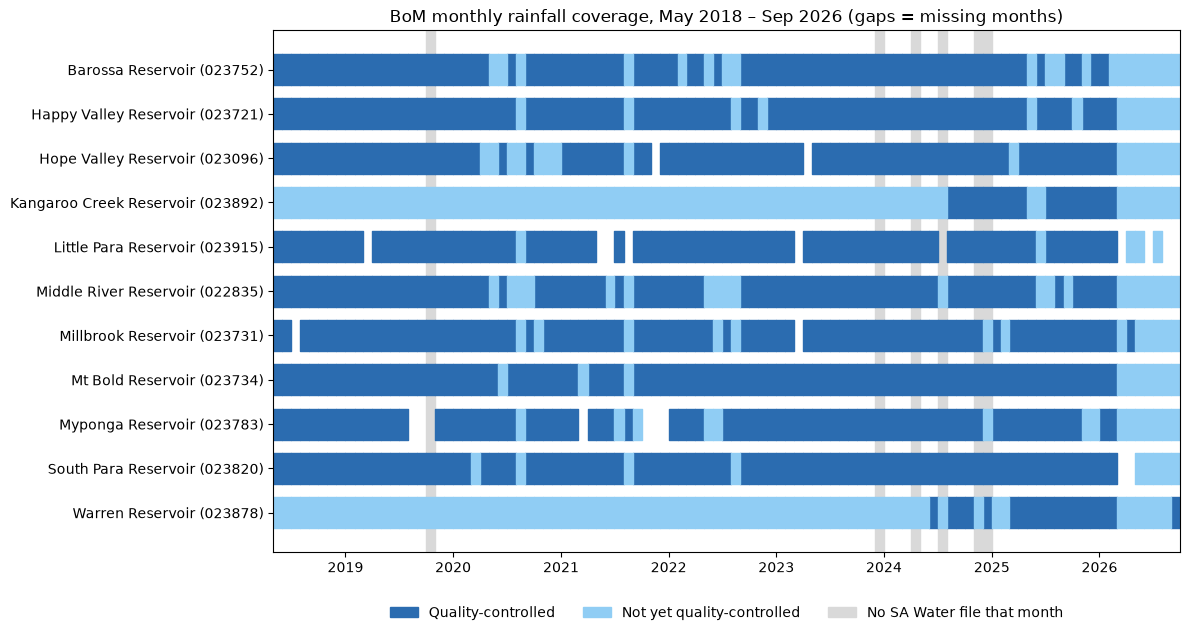

In [29]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

station_to_reservoir = {v: k for k, v in configure.RAIN_STATIONS.items()}
sawater_months = set(unified_columns_raw["month"].dropna())
no_file_months = all_months.difference(sawater_months)

def spans(dates):
    """One (start, width) block per month, in matplotlib date units."""
    starts = mdates.date2num(dates - pd.offsets.MonthBegin(1))
    widths = mdates.date2num(dates) - starts + 1
    return list(zip(starts, widths))

stations = sorted(window["Station number"].unique(),
                  key=lambda s: station_to_reservoir.get(s, s), reverse=True)

fig, ax = plt.subplots(figsize=(12, 0.45 * len(stations) + 1.5))

# Grey bands: months with no SA Water file
for d in no_file_months:
    ax.axvspan(*mdates.date2num([d - pd.offsets.MonthBegin(1), d + pd.Timedelta(days=1)]),
               color="0.85", zorder=0)

for i, stn in enumerate(stations):
    g = window[window["Station number"] == stn]
    qc = pd.DatetimeIndex(g.loc[g["Quality"] == "Y", "date"])
    not_qc = pd.DatetimeIndex(g.loc[g["Quality"] != "Y", "date"])
    ax.broken_barh(spans(qc), (i - 0.35, 0.7), color="#2b6cb0")
    ax.broken_barh(spans(not_qc), (i - 0.35, 0.7), color="#90cdf4")

ax.set_yticks(range(len(stations)))
ax.set_yticklabels([f"{station_to_reservoir.get(s, '?')} ({s})" for s in stations])
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(mdates.date2num(all_months[0] - pd.offsets.MonthBegin(1)),
            mdates.date2num(all_months[-1]) + 1)
ax.set_title("BoM monthly rainfall coverage, May 2018 – Sep 2026 (gaps = missing months)")
ax.legend(handles=[Patch(color="#2b6cb0", label="Quality-controlled"),
                   Patch(color="#90cdf4", label="Not yet quality-controlled"),
                   Patch(color="0.85", label="No SA Water file that month")],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

### Findings: BoM
Used to inform `combine_rainfall()`

- All 11 stations are present and match the mapping to the 11 Reservoirs
- 5 stations have at least one month of a gap where rainfall wasn't recorded, with the most gaps (10 non-consecutive months) coming from 023915 Little Para Reservoir. Consider filling these gaps by using values from the most correlated station, rather than average interpolation between the last month and the next (which would be misleading.)
- Nearly all records for 2026 months across nearly all reservoirs are `Quality = N`. Every reservoir has at least a few `Quality = N` months even before 2026, with the most coming from 023878 Warren Reservoir
- State the limitations of gaps and `Quality = N`, especially during test period in forecasting model, as limitations in the report